# Skills demand

### Questions to ask:
- Now that titles are bucketed into role (Analyst/Scientist/Engineer/Specialist) and
  seniority, how is the market actually split across those buckets?
- Which skills (from `description_tokens`) show up most, and does that differ by role
  bucket?

This notebook starts with the title categorization built out in `data_prep.py`
(`add_title_category`), then moves into the skills-in-demand analysis.

## Preparation
- Import necessary packages
- Load data
    - cleaning logic is managed by the Python script in a separate file.
    - Display first few records to check if it loaded
- Data collection window

In [1]:
# --- Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

In [2]:
# Call functions to run source file check and clean up, prepare the dataframe
import sys
sys.path.append("../src")
from data_prep import load_and_clean, top_n_values

df = load_and_clean("../raw/gsearch_jobs.csv")
df.head()

,title,company_name,location,via,description,extensions,job_id,thumbnail,posted_at,schedule_type,work_from_home,salary,search_term,date_time,search_location,commute_time,salary_pay,salary_rate,salary_avg,salary_min,salary_max,salary_hourly,salary_yearly,salary_standardized,description_tokens,skills_list,ext_time,ext_salary_text,ext_flags,flag_health_insurance,flag_no_degree_mentioned,via_clean,hours_since_posted,posted_date,state,location_type,title_role,title_seniority,title_level_numeral
0,Data Analyst,Meta,Anywhere,via LinkedIn,"In the intersection of compliance and analytics, we are seeking an analytical and data-savvy sel...","['15 hours ago', '101K–143K a year', 'Work from home', 'Full-time']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2NpZCI6IlhBR01sSV93cUdRQUFBQUFBQUFBQUE9PSIsInV1bGUi...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSGWd4ZbDsuXA2YQ7fwMam4nW4cokBZJJYHlWXaRfs&s,15 hours ago,Full-time,True,101K–143K a year,data analyst,2023-08-04 03:00:13.797776,United States,NaN,101K–143K,a year,122000.0,101000.0,143000.0,NaN,122000.0,122000.0,"['tableau', 'r', 'python', 'sql']","[tableau, r, python, sql]",[15 hours ago],[101K–143K a year],"[Work from home, Full-time]",False,False,LinkedIn,15.0,2023-08-03 12:00:13.797776,NaN,Remote,Data Analyst,Not specified,NaN
1,Data Analyst,ATC,United States,via LinkedIn,Job Title: Entry Level Business Analyst / Product Owner U.S. Citizens and those authorized to wo...,"['12 hours ago', 'Full-time', 'Health insurance']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2NpZCI6InJ4WUhwWTd4aTNRQUFBQUFBQUFBQUE9PSIsInV1bGUi...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS9pL2p8JqLIXvaGeM9_bc7EXVkXWuBzWI204SfKIU&s,12 hours ago,Full-time,NaN,NaN,data analyst,2023-08-04 03:00:13.797776,United States,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[],[],[12 hours ago],[],"[Full-time, Health insurance]",True,False,LinkedIn,12.0,2023-08-03 15:00:13.797776,NaN,Nationwide/Unspecified,Data Analyst,Not specified,NaN
2,Aeronautical Data Analyst,"Garmin International, Inc.","Olathe, KS",via Indeed,"Overview:\n\nWe are seeking a full-time...\nAeronautical Data Analyst in our Olathe, KS location...","['18 hours ago', 'Full-time']",eyJqb2JfdGl0bGUiOiJBZXJvbmF1dGljYWwgRGF0YSBBbmFseXN0IiwiaHRpZG9jaWQiOiJtU2xQSUxycndaY0FBQUFBQUFB...,NaN,18 hours ago,Full-time,NaN,NaN,data analyst,2023-08-04 03:00:13.797776,United States,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,['sql'],[sql],[18 hours ago],[],[Full-time],False,False,Indeed,18.0,2023-08-03 09:00:13.797776,KS,Specific location,Data Analyst,Not specified,NaN
3,Data Analyst - Consumer Goods - Contract to Hire,Upwork,Anywhere,via Upwork,Enthusiastic Data Analyst for processing sales data in Excel and communicate with clients. Hours...,"['12 hours ago', '15–25 an hour', 'Work from home', 'Contractor', 'No degree mentioned']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgLSBDb25zdW1lciBHb29kcyAtIENvbnRyYWN0IHRvIEhpcmUiLCJodGlkb2Np...,NaN,12 hours ago,Contractor,True,15–25 an hour,data analyst,2023-08-04 03:00:13.797776,United States,NaN,15–25,an hour,20.0,15.0,25.0,20.0,NaN,41600.0,"['powerpoint', 'excel', 'power_bi']","[powerpoint, excel, power_bi]",[12 hours ago],[15–25 an hour],"[Work from home, Contractor, No degree mentioned]",False,True,Upwork,12.0,2023-08-03 15:00:13.797776,NaN,Remote,Data Analyst,Not specified,NaN
4,Data Analyst | Workforce Management,Krispy Kreme,United States,via LinkedIn,Overview of Position\n\nThis position will be the primary person responsible for all Workforce M...,"['7 hours ago', '90K–110K a year', 'Contractor']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgfCBXb3JrZm9yY2UgTWFuYWdlbWVudCIsImh0aWRvY2lkIjoibUhMMHlaX1Rr...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRRV1lShEQRsstSpp3yi846fCWv72q10JAm0_pNpHc&s,7 hours ago,Contractor,NaN,90K–110K a year,data analyst,2023-08-04 03:00:13.797776,United States,NaN,90K–110K,a year,100000.0,90000.0,110000.0,NaN,100000.0,100000.0,"['powerpoint', 'excel', 'outlook', 'word']","[powerpoint, excel, outlook,

In [3]:
start_date = df["posted_date"].min().strftime("%B %d, %Y")
end_date = df["posted_date"].max().strftime("%B %d, %Y")

display(Markdown(f"**Data collection window:** {start_date} to {end_date}"))

**Data collection window:** November 03, 2022 to April 18, 2025

## Job title categorization

`load_and_clean` now tags every posting with two independent dimensions,
derived from the word-frequency pass in `01_eda_data_analyst_jobs.ipynb`
(Step 9) rather than assumed up front:

- **`title_role`** -- what kind of work: Data Analyst, Data Scientist, Data
  Engineer, or Data Specialist/Other (the catch-all for specialist, developer,
  consultant, associate, architect, governance, quality titles, and anything
  with none of the role words). Loosely follows the Google Data Analyst
  Professional Certificate's 3-path framework, with Engineer kept as its own
  bucket rather than folded into Specialist -- whenever a title mentions
  "engineer" at all, it's categorized as Engineer, even if it also mentions
  analyst/analytics. Whenever 'Analysis' or 'Analyst' was mentioned, 
  the posting was categorized in 'Data Analyst' bucket. 
  When 'Data Science' was mentioned without 'Analysis' or 'Analyst' keyword, the posting was categorized in 'Data Scientist' bucket.
- **`title_seniority`** -- how senior: Director, Manager, Principal, Staff,
  Lead, Senior, Junior, Entry-level, Intern, or "Not specified." Manager and
  Director are treated as a seniority tier here, not a separate role, since a
  title like "Data Analyst Manager" describes a level on top of an Analyst
  role rather than a different kind of work.

A separate `title_level_numeral` column keeps any standalone roman numeral
("Data Analyst II") as a raw, un-interpreted signal. There's no reliable way
to know from the data alone what a given company's numeral actually means, so
it isn't forced onto the seniority scale above.

,count,pct_of_rows
title_role,,
Data Analyst,52382,84.6
Data Specialist/Other,4114,6.6
Data Scientist,3425,5.5
Data Engineer,2032,3.3


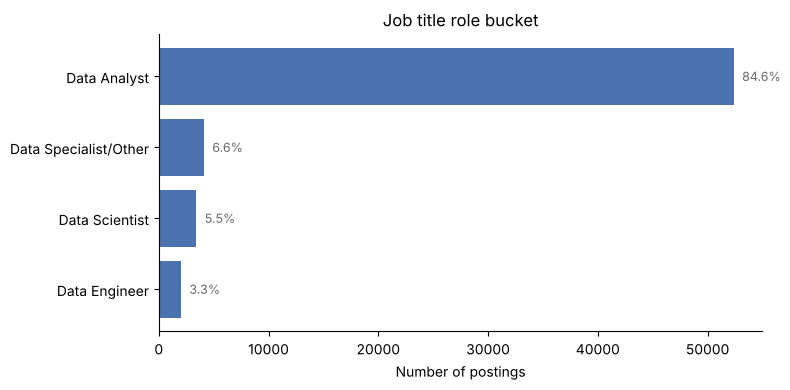

In [4]:
# Role bucket distribution
role_counts = df["title_role"].value_counts()
role_pct = (role_counts / len(df) * 100).round(1)
role_table = pd.DataFrame({"count": role_counts, "pct_of_rows": role_pct})
display(role_table)

fig, ax = plt.subplots(figsize=(8, 4))
order = role_counts.index[::-1]
bars = ax.barh(order, role_counts.loc[order], color="#4C72B0")
ax.set_xlabel("Number of postings")
ax.set_title("Job title role bucket")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for bar, label in zip(bars, order):
    ax.annotate(f"{role_pct.loc[label]}%", xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="dimgray")
plt.tight_layout()
plt.show()

Data Analyst dominates, as expected given how the search was scoped, but Scientist,
Engineer, and Specialist/Other together still make up about 1 in 6 postings, so the
role split is worth keeping in mind whenever a later chart just says "data analyst jobs."

,count,pct_of_rows
title_seniority,,
Not specified,45427,73.3
Senior,9613,15.5
Lead,1966,3.2
Manager,1576,2.5
Intern,860,1.4
Junior,659,1.1
Entry-level,652,1.1
Principal,633,1.0
Director,327,0.5


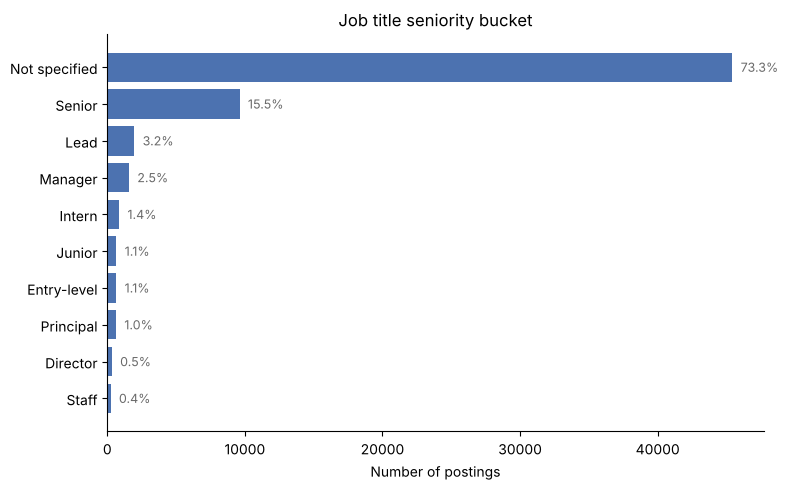

In [5]:
# Seniority bucket distribution
seniority_counts = df["title_seniority"].value_counts()
seniority_pct = (seniority_counts / len(df) * 100).round(1)
seniority_table = pd.DataFrame({"count": seniority_counts, "pct_of_rows": seniority_pct})
display(seniority_table)

fig, ax = plt.subplots(figsize=(8, 5))
order = seniority_counts.index[::-1]
bars = ax.barh(order, seniority_counts.loc[order], color="#4C72B0")
ax.set_xlabel("Number of postings")
ax.set_title("Job title seniority bucket")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for bar, label in zip(bars, order):
    ax.annotate(f"{seniority_pct.loc[label]}%", xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="dimgray")
plt.tight_layout()
plt.show()

Most postings (about 3 in 4) don't carry an explicit seniority word in the title at
all. "Not specified" is the largest group by a wide margin, bigger than Senior and
every other tier combined. Worth remembering before reading too much into any
seniority-split comparison downstream: most of this data simply doesn't say.

## Skills in demand

`skills_list` (parsed from `description_tokens`) turns out to be a much cleaner field than `title` was: it's a controlled vocabulary of only 134 distinct skill tokens across the whole dataset, not free text, so there's no stopword-stripping or phrase-joining needed here.

78.4% of postings (48,601 of 61,953) have at least one skill tagged; the other 21.6% have none listed at all. Among postings with any skills tagged, the median is 4 (mean ~4.2, up to 25 in one posting).

In [6]:
from collections import Counter

# Display-label overrides for tokens where a straight title-case would read oddly
# (acronyms, mixed-case product names). Anything not listed here just gets
# underscores replaced with spaces and title-cased.
SKILL_LABEL_OVERRIDES = {
    "sql": "SQL", "r": "R", "sas": "SAS", "aws": "AWS", "gcp": "GCP",
    "vba": "VBA", "sap": "SAP", "ssrs": "SSRS", "ssis": "SSIS", "dax": "DAX",
    "nosql": "NoSQL", "javascript": "JavaScript", "mysql": "MySQL",
    "bigquery": "BigQuery", "powerpoint": "PowerPoint", "sharepoint": "SharePoint",
    "power_bi": "Power BI", "go": "Go", "c": "C", "microstrategy": "MicroStrategy",
    "spss": "SPSS",
}

def skill_label(token):
    return SKILL_LABEL_OVERRIDES.get(token, token.replace("_", " ").title())

skill_counts = Counter()
for skills in df["skills_list"]:
    skill_counts.update(skills)

TOP_N = 20
top_skills = pd.Series(skill_counts).sort_values(ascending=False).head(TOP_N)
top_skills_table = pd.DataFrame({
    "count": top_skills,
    "pct_of_postings": (top_skills / len(df) * 100).round(1),
})
top_skills_table.index = [skill_label(t) for t in top_skills_table.index]
display(top_skills_table)

,count,pct_of_postings
SQL,31006,50.0
Excel,19779,31.9
Python,18793,30.3
Power BI,17420,28.1
Tableau,16823,27.2
R,11342,18.3
SAS,5317,8.6
PowerPoint,4411,7.1
Word,4365,7.0
Azure,3887,6.3


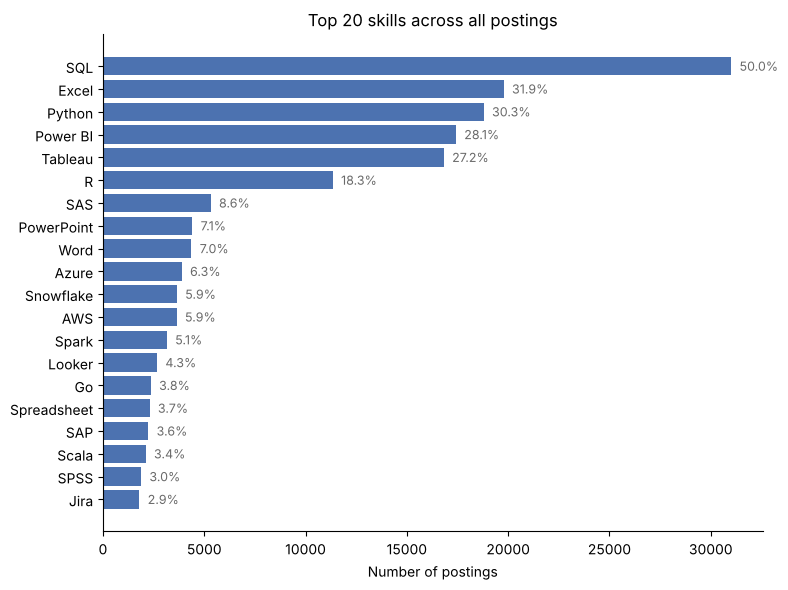

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
order = top_skills_table.index[::-1]
bars = ax.barh(order, top_skills_table.loc[order, "count"], color="#4C72B0")
ax.set_xlabel("Number of postings")
ax.set_title(f"Top {TOP_N} skills across all postings")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for bar, label in zip(bars, order):
    pct = top_skills_table.loc[label, "pct_of_postings"]
    ax.annotate(f"{pct}%", xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="dimgray")
plt.tight_layout()
plt.show()

SQL, Excel, and Python lead by a wide margin, each showing up in roughly a quarter to half of all postings with Power BI and Tableau close behind, confirming BI/visualization tools are nearly as much a baseline expectation as the core languages. Percentages are of *all* postings (61,953), including the 21.6% with no skills tagged at all, so they're a floor, not a ceiling, on how often each skill is actually expected.

Worth noting PowerPoint (7.1%) and Word (7.0%) made the top 20 at all. These aren't analytical tools, they're how findings get communicated. The role split later in this notebook shows why: both are roughly 2-3x more common in Data Analyst postings (7.9% / 7.8%) than in Data Scientist or Data Engineer postings (2.9% / 2.3% and 3.4% / 2.8%). Presenting and writing up results for a non-technical audience reads as a distinctly Analyst-flavored expectation, not a universal one.

## Skills by job role

What relationship exists between role bucket and skills? The following **heatmap** shows a role-by-skill grid, and color is the *share of postings within that role bucket* mentioning the skill instead of a raw count, since the role buckets are very different sizes (Data Analyst alone is 52,382 postings vs. Data Engineer's 2,032) and raw counts would just reflect bucket size rather than actual demand.

In [8]:
role_order = df["title_role"].value_counts().index.tolist()
top_skill_tokens = top_skills.index[:15].tolist()  # reuses top_skills from the section above

heatmap_data = pd.DataFrame(index=top_skill_tokens, columns=role_order, dtype=float)
for role in role_order:
    role_df = df[df["title_role"] == role]
    role_skill_counts = Counter()
    for skills in role_df["skills_list"]:
        role_skill_counts.update(skills)
    for skill in top_skill_tokens:
        heatmap_data.loc[skill, role] = role_skill_counts.get(skill, 0) / len(role_df) * 100

heatmap_data.index = [skill_label(t) for t in heatmap_data.index]
heatmap_data.round(1)

,Data Analyst,Data Specialist/Other,Data Scientist,Data Engineer
SQL,51.2,25.1,53.6,65.7
Excel,35.2,18.7,9.1,11.4
Python,27.8,13.7,72.8,56.4
Power BI,30.4,14.0,15.1,20.5
Tableau,29.2,10.5,20.2,19.4
R,18.0,8.1,39.6,11.9
SAS,9.1,4.1,9.3,4.1
PowerPoint,7.9,2.7,2.9,3.4
Word,7.8,3.2,2.3,2.8
Azure,5.1,6.3,12.8,25.0


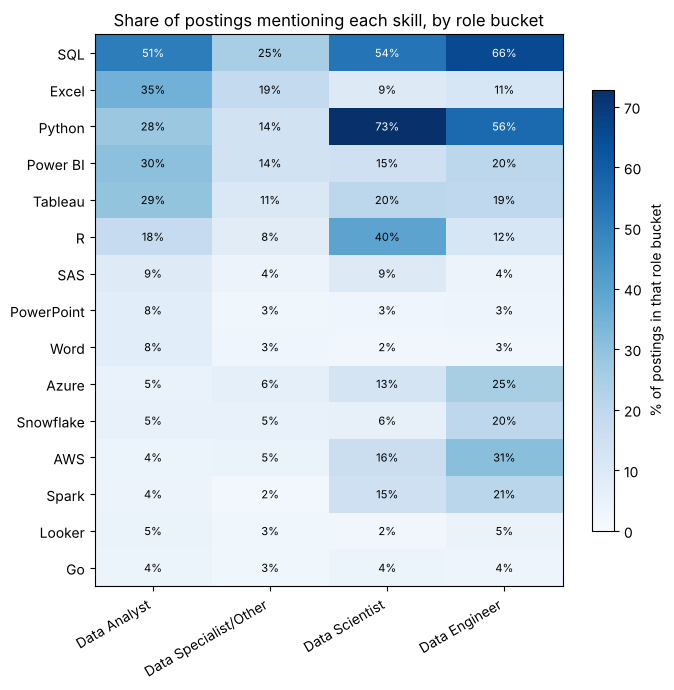

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(heatmap_data.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(role_order)))
ax.set_xticklabels(role_order, rotation=30, ha="right")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
ax.set_title("Share of postings mentioning each skill, by role bucket")

vmax = heatmap_data.values.max()
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        val = heatmap_data.values[i, j]
        color = "white" if val > vmax * 0.6 else "black"
        ax.text(j, i, f"{val:.0f}%", ha="center", va="center", color=color, fontsize=8)

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("% of postings in that role bucket")
plt.tight_layout()
plt.show()

The split is real, not noise: Python shows up in about 73% of Data Scientist postings vs. 28% of Data Analyst postings, and R follows the same pattern (40% vs. 18%). Cloud/pipeline tools -- Azure, AWS, Snowflake, Spark -- all climb sharply for Data Engineer, while Excel, PowerPoint, Word, Power BI, and Tableau skew toward Data Analyst. SQL is the one skill that's consistently high across every bucket (51-66%), which tracks with it being the closest thing to a universal baseline skill in this field.

One caveat on reading this precisely: Data Engineer is the smallest bucket (2,032 postings) and Data Specialist/Other the second smallest (4,114), so their percentages carry more sampling noise than Data Analyst's (52,382).

## Unique opportunities in Data Specialist/Other

The Specialist/Other catch-all (4,114 postings, 6.6%) is really two different populations stitched together: 42.4% is Upwork gig postings ("Excel help", "I need an expert in R"), and the other 57.6% (2,370 postings) are genuine job-board listings. The interesting niches live almost entirely in that second group, so the numbers below exclude Upwork.

In [10]:
non_gig = df[(df["title_role"] == "Data Specialist/Other") & (df["via_clean"] != "Upwork")]
print(f"Non-gig Specialist/Other postings: {len(non_gig):,}")

# Data Governance & Quality: a distinct, well-paid niche
gov_mask = non_gig["title"].str.contains("governance|quality", case=False, na=False, regex=True)
print(f"\nData Governance / Quality cluster: {gov_mask.sum()} postings")
print(f"Median salary (where disclosed): "
      f"${non_gig.loc[gov_mask, 'salary_standardized'].median():,.0f}")
print(f"vs. this bucket's overall median (non-gig): "
      f"${non_gig['salary_standardized'].median():,.0f}")
print(f"vs. Data Analyst bucket median: "
      f"${df.loc[df['title_role'] == 'Data Analyst', 'salary_standardized'].median():,.0f}")
display(non_gig.loc[gov_mask, "title"].value_counts().head(8))

Non-gig Specialist/Other postings: 2,370

Data Governance / Quality cluster: 167 postings
Median salary (where disclosed): $116,950
vs. this bucket's overall median (non-gig): $112,000
vs. Data Analyst bucket median: $85,280


title
Data Governance Specialist                                            17
Data Governance Lead                                                  16
Data Governance                                                       13
Data Quality Specialist                                                5
Data Quality Lead                                                      5
Data Governance Specialist - Master Data Management                    4
Head of Data Strategy, Acquisition & Governance                        4
Southwest Airlines Data Entry Jobs ||Remote|| - Quality Control...     3
Name: count, dtype: int64

Data Governance and Data Quality roles form the clearest standout: 167 postings -- Data Governance Specialist, Data Governance Lead, Data Quality Lead, Master Data Management -- with a median disclosed salary above both this bucket's own median and the Data Analyst bucket's median. It's easy to miss entirely if a job search only targets the word "Analyst."

In [11]:
# Highest-paid postings in this bucket -- what kind of "data" work pays the most
# outside the three main role buckets?
top_paid = (non_gig.dropna(subset=["salary_standardized"])
            .sort_values("salary_standardized", ascending=False)
            .drop_duplicates(subset=["title", "company_name"])
            .head(8))
display(top_paid[["title", "company_name", "salary_standardized"]])

,title,company_name,salary_standardized
3472,Quantitative Researcher - Fundamental Equities,Non-Disclosed,550000.0
26274,Lead Quantitative Researcher - Equity Stat Arb,Algo Capital Group,475000.0
28803,Data Architect | Informatica | Onsite | US,Photon,260700.0
3679,"Manager, Data Delivery",Balyasny Asset Management L.P.,250000.0
6186,Data Privacy and Cybersecurity Associate,LHH,237500.0
5723,Actuary Lead – P&C Pricing and Reserving Actuary Team,USAA,230695.0
16536,Data & AI Sales Executives - FMCG or FS,ON Data Staffing,225000.0
37022,Chief Data Officer,KDR Talent USA,210000.0


They're evidence of how a data career branches once the basic competencies are in place. Quantitative Researcher ($550,000 and $475,000) is the industry-vertical axis: the same core skills, aimed at finance/quant funds, command a very different ceiling. Data Architect ($260,700) is the skill-combination axis: depth in data modeling and systems design rather than analysis itself. Chief Data Officer ($210,000) and VP of Data Governance ($176,800) are the leadership axis: the same foundation, but the career runs up through management instead of deeper into a technical specialty. None of these exist as a distinct path in the other three role buckets -- which is the point: past a certain level, "data professional" isn't one career, it's a starting point for several.

In [12]:
# A couple of genuinely unusual niches, visible only once you look past the
# aggregate numbers
print("Field Data Collector postings:", (non_gig["title"] == "Field Data Collector").sum(),
      "-- all from NORC at the University of Chicago (in-person survey/field research,")
print("                                 not desk analytics)")
print("Data Librarian postings:", non_gig["title"].str.contains("Librarian", case=False, na=False).sum(),
      "-- all Oklahoma City, OK")

Field Data Collector postings: 44 -- all from NORC at the University of Chicago (in-person survey/field research,
                                 not desk analytics)
Data Librarian postings: 14 -- all Oklahoma City, OK


These aren't noise to filter out -- they're the part of the market a title search for "Data Analyst" or "Data Scientist" alone would never surface: Data Governance/Quality as a distinctly well-paid specialization, an executive-level data leadership track, and a scatter of industry-specific niches (field research, library science, quant finance) that use "data" skills in contexts well outside a conventional analyst job description.

## Conclusion

Title categorization splits postings into four role buckets -- Data Analyst (84.6%), Data Specialist/Other (6.6%), Data Scientist (5.5%), Data Engineer (3.3%) -- plus a separate seniority dimension, where "Not specified" (73.3%) dwarfs every named tier, including Senior (15.5%).

Skill demand is not uniform across those buckets. SQL is the one constant, appearing in 51-66% of postings regardless of role. Past that, the split is sharp: Python and R are a Data Scientist signature (73% and 40%, vs. 28% and 18% for Data Analyst), cloud/pipeline tools -- Azure, AWS, Snowflake, Spark -- climb for Data Engineer, and Office/BI tools (Excel, PowerPoint, Power BI, Tableau) stay Analyst-leaning.

The Specialist/Other catch-all, once Upwork gig noise and the reclassified Data Science titles are set aside, surfaces real niches a straightforward "Data Analyst" search would miss -- and read together, they tell a bigger story than any one of them alone. Data Governance/Quality ($116,950 median), Quantitative Researcher roles at finance/quant funds ($550,000+), Data Architect ($260,700), and an executive track (Chief Data Officer, VP of Data Governance) each represent a different axis a data career can branch down once the basic competencies are in place: industry vertical, technical specialization, or the leadership track. "Data professional" turns out to be less a single job than a starting point for many, depending on interests, experience, industry, and which skills get layered on next.